# 01 · 인기 장소 불러오기와 정리

제주관광빅데이터플랫폼 **제주 지역별 인기 장소**(티맵 내비 도착) 파일을 정리한다.

- 이 파일은 그 달 도착 2건 이상인 **모든 목적지**다. 관광지만 남기고, 너무 작은 곳은 뺀다.
- 행이 없는 달은 도착 0~1건이므로 0으로 채운다.
- 엑셀은 104만 행까지만 열려서 이 파일(약 137만 행)은 잘린다. 꼭 여기서 다룬다.

**결과물** (`data/processed/`)
- `month_total.csv` 월별 전체 도착 합 (비중을 낼 때 나누는 값)
- `places.csv` 관광지 목록과 기준 기간 월평균 도착, 분석에 쓸지(`keep`)
- `place_month.csv` 분석에 쓰는 관광지 × 월 도착 수 (관광객·도민 따로)

In [1]:
from pathlib import Path
import platform
import pandas as pd
import matplotlib.pyplot as plt

# 옵션(BASE_YEARS, MIN_AVG, TOURISM_CATS 등)은 00_settings.ipynb에서 바꾼다
%run settings.py
print(f"기준 연도 {BASE_YEARS} · 월평균 도착 {MIN_AVG}건 이상 · 관광 카테고리 {len(TOURISM_CATS)}종")

# 한글 글꼴 (그래프 제목이 네모로 깨지지 않게)
plt.rcParams["font.family"] = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

RAW = Path("../data/raw/제주_지역별_인기_장소.csv")   # 내려받은 파일 위치
OUT = Path("../data/processed")
OUT.mkdir(parents=True, exist_ok=True)

기준 연도 [2024, 2025] · 월평균 도착 50건 이상 · 관광 카테고리 39종


## 1. 불러오기

In [2]:
cols = {
    "주행일자(YYYYMM)": "ym", "목적지명": "name", "목적지주소": "addr", "읍면동코드": "emd_code",
    "읍면동명": "emd", "도착건수": "arrive", "카테고리 3단계": "cat",
    "관광객 도착 수": "tourist", "도민 도착 수": "local",
}
df = pd.read_csv(RAW, encoding="utf-8-sig", usecols=list(cols),
                 dtype={"목적지명": "string", "목적지주소": "string", "읍면동명": "string", "카테고리 3단계": "string"})
df = df.rename(columns=cols)
df["year"] = df["ym"] // 100
print(f"{len(df):,}행 · {df.ym.min()}~{df.ym.max()} · {df.ym.nunique()}개월")
df.head()

1,369,138행 · 202101~202512 · 60개월


,ym,name,addr,emd_code,emd,arrive,cat,tourist,local,year
0,202512,곁,제주 제주시 일도일동 1401-15,39010510,일도1동,7,바,3,4,2025
1,202512,곶,제주 제주시 이도이동 2021-16,39010540,이도2동,8,미용실,0,8,2025
2,202512,끈,제주 서귀포시 서귀동 573-1,39020510,송산동,13,쇼핑기타,11,2,2025
3,202512,닻,제주 제주시 애월읍 하귀2리 2726-0,39010120,애월읍,13,일본선술집,9,3,2025
4,202512,뜰,제주 제주시 연동 252-1,39010650,연동,24,꼬치전문점,2,22,2025


## 2. 확인

가장 작은 도착건수: 2 → 2건 미만인 달은 행이 없다
도착건수 ≠ 관광객 + 도민 인 행: 7.9% → 관광객 비중은 관광객 ÷ (관광객 + 도민)으로 계산


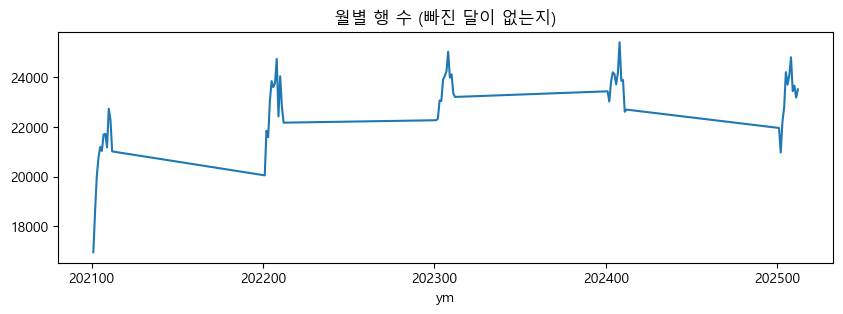

In [3]:
print("가장 작은 도착건수:", df.arrive.min(), "→ 2건 미만인 달은 행이 없다")
mismatch = df.arrive != df.tourist + df.local
print(f"도착건수 ≠ 관광객 + 도민 인 행: {mismatch.mean():.1%} → 관광객 비중은 관광객 ÷ (관광객 + 도민)으로 계산")

df.groupby("ym").size().plot(figsize=(10, 3), title="월별 행 수 (빠진 달이 없는지)");

## 3. 월별 전체 도착 합 (나누는 값)

카테고리 상관없이 그 달 모든 목적지의 도착을 더한다. 같은 파일이라 집계 방식이 분자·분모에 똑같이 적용된다.

In [4]:
month_total = df.groupby("ym", as_index=False)["arrive"].sum().rename(columns={"arrive": "total"})
month_total.to_csv(OUT / "month_total.csv", index=False, encoding="utf-8-sig")

(month_total.groupby(month_total.ym // 100)["total"].sum() / 1e6).round(2).rename("연간 도착(백만 건)")

ym
2021    19.37
2022    19.99
2023    17.01
2024    15.13
2025    13.89
Name: 연간 도착(백만 건), dtype: float64

## 4. 관광지만 남기기

`카테고리 3단계` 중 `TOURISM_CATS`(00_settings에서 고친다)에 든 항목만 관광지로 본다.

In [5]:
tour = df[df["cat"].isin(TOURISM_CATS)].copy()
# 같은 이름이 여러 곳에 있다(민오름, 붉은오름 등) → 이름 + 읍면동코드로 한 곳을 구분
tour["place_id"] = tour["name"] + "|" + tour["emd_code"].astype(str)
print(f"관광 카테고리: {len(tour):,}행 · {tour.place_id.nunique():,}곳")
tour["cat"].value_counts().head(50)

관광 카테고리: 48,599행 · 1,633곳


cat
관광명소기타        7518
오름            5244
공원            4951
여행/레저기타       3959
박물관/기념관       3461
포구            1939
해수욕장          1890
문화유적지         1822
화랑/전시관        1801
명산            1588
드라이브코스        1510
체험학습          1343
테마파크          1220
미술관           1151
폭포/계곡         1026
목장             972
동식물원           956
동굴             619
섬              607
관광농원           601
전망대            550
관광단지           471
등대             440
자연휴양림          414
고택/생가/민속마을     371
과학관            261
성              241
종합위락시설         212
산림욕장           191
기념비            182
촬영지            177
도립공원           168
놀이공원           137
탑              117
국립공원           116
수족관            109
정자             103
호수             101
염전              60
Name: count, dtype: Int64

## 5. 관광지 × 월 표 만들기 (빈 달은 0)

In [6]:
pm = tour.groupby(["place_id", "ym"], as_index=False)[["arrive", "tourist", "local"]].sum()

months = sorted(df["ym"].unique())
grid = pd.MultiIndex.from_product([pm["place_id"].unique(), months], names=["place_id", "ym"])
pm = pm.set_index(["place_id", "ym"]).reindex(grid, fill_value=0).reset_index()
print(f"{pm.place_id.nunique():,}곳 × {len(months)}개월 = {len(pm):,}행")

1,633곳 × 60개월 = 97,980행

## 6. 너무 작은 곳 빼기

기준 기간(`BASE_YEARS`) 월평균 도착이 `MIN_AVG`건 미만이면 비중이 크게 흔들려서 뺀다.

In [7]:
info = (tour.sort_values("ym").groupby("place_id")
          .agg(name=("name", "last"), addr=("addr", "last"), emd=("emd", "last"), cat=("cat", "last")))

base = pm[(pm.ym // 100).isin(BASE_YEARS)]
stat = base.groupby("place_id").agg(base_arrive=("arrive", "sum"),
                                     base_months=("arrive", lambda s: int((s > 0).sum())))
stat["avg"] = (stat.base_arrive / (12 * len(BASE_YEARS))).round(1)
info = info.join(stat).fillna({"base_arrive": 0, "base_months": 0, "avg": 0})
info["keep"] = info["avg"] >= MIN_AVG

print(f"관광지 {len(info):,}곳 중 월평균 {MIN_AVG}건 이상: {info.keep.sum():,}곳")
info.sort_values("avg", ascending=False).head(40)

관광지 1,633곳 중 월평균 50건 이상: 365곳


,name,addr,emd,cat,base_arrive,base_months,avg,keep
place_id,,,,,,,,
함덕해수욕장|39010140,함덕해수욕장,제주 제주시 조천읍 함덕리 산 14-1,조천읍,해수욕장,157574,24,6565.6,True
성산일출봉|39020130,성산일출봉,제주 서귀포시 성산읍 성산리 114-0,성산읍,명산,148652,24,6193.8,True
협재해수욕장|39010110,협재해수욕장,제주 제주시 한림읍 협재리 0-0,한림읍,해수욕장,126758,24,5281.6,True
오설록티뮤지엄|39020310,오설록티뮤지엄,제주 서귀포시 안덕면 서광리 1235-1,안덕면,박물관/기념관,111282,24,4636.8,True
아쿠아플라넷/제주|39020130,아쿠아플라넷/제주,제주 서귀포시 성산읍 고성리 127-3,성산읍,수족관,87049,24,3627.0,True
섭지코지|39020130,섭지코지,제주 서귀포시 성산읍 고성리 127-2,성산읍,관광명소기타,79328,24,3305.3,True
이호테우해변|39010680,이호테우해변,제주 제주시 이호일동 0-0,이호동,해수욕장,76476,24,3186.5,True
곽지해수욕장|39010120,곽지해수욕장,제주 제주시 애월읍 곽지리 0-0,애월읍,해수욕장,73476,24,3061.5,True
김녕해수욕장|39010130,김녕해수욕장,제주 제주시 구좌읍 김녕리 497-4,구좌읍,해수욕장,68601,24,2858.4,True


## 7. 저장

In [8]:
keep_ids = info.index[info["keep"]]
place_month = (pm[pm.place_id.isin(keep_ids)]
               .merge(info[["name", "emd", "cat"]], left_on="place_id", right_index=True))
place_month.to_csv(OUT / "place_month.csv", index=False, encoding="utf-8-sig")
info.reset_index().sort_values("avg", ascending=False).to_csv(OUT / "places.csv", index=False, encoding="utf-8-sig")
print(f"place_month.csv {len(place_month):,}행 · places.csv {len(info):,}곳 (keep {len(keep_ids):,}곳)")

place_month.csv 21,900행 · places.csv 1,633곳 (keep 365곳)


## 8. 눈으로 확인

억새 명소라면 10~11월에 비중이 올라야 한다.

Text(0.5, 0, '')

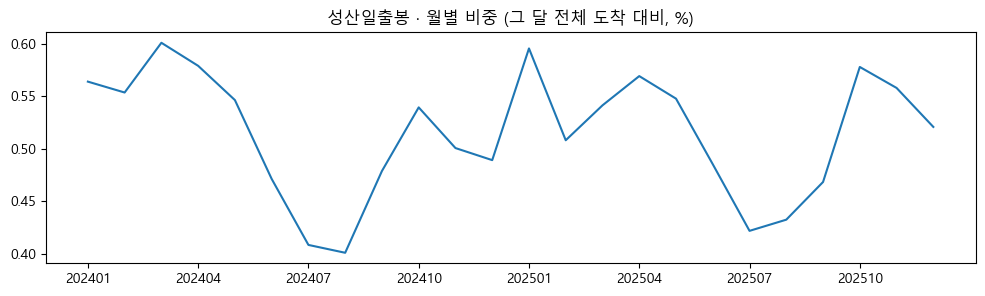

In [9]:
name = EXAMPLE_STEADY
x = place_month[place_month["name"] == name].merge(month_total, on="ym")
x["share"] = x.arrive / x.total * 100
x = x[(x.ym // 100).isin(BASE_YEARS)]   # 기준 연도만 남기기
x["ym"] = x["ym"].astype(str)
ax = x.plot(x="ym", y="share", figsize=(12, 3), legend=False, title=f"{name} · 월별 비중 (그 달 전체 도착 대비, %)")

step = 3
ax.set_xticks(range(0, len(x), step))
ax.set_xticklabels(x["ym"].iloc[::step], rotation=0)

ax.set_xlabel("")

다음: `02_index` 에서 제철 지수(월 비중 ÷ 12개월 평균 비중)를 계산한다.